# Proyecto: Machine Learning y Deep Learning Aplicados (UTEC)
## Tarea 2: Clasificación de Textos en AG News (4 Clases)
**Profesor:** Marcelo Jafett Contreras Cabrera  
**Entorno de Ejecución:** Local con aceleración GPU (PyTorch AMP FP16/TF32)

---
### 1. Definición del Problema Matemático
Se formaliza el problema de clasificación de textos de noticias en $C=4$ categorías:
1. **World** (Mundo)
2. **Sports** (Deportes)
3. **Business** (Negocios)
4. **Sci/Tech** (Ciencia y Tecnología)

Dado un texto no estructurado $x = (w_1, w_2, \dots, w_T)$, se busca una hipótesis $f_\theta(x) \in \{0, 1, 2, 3\}$.
La optimización minimiza la pérdida de entropía cruzada multiclase:
$$\mathcal{L}(\theta) = -\frac{1}{N} \sum_{i=1}^N \sum_{c=1}^4 y_{i,c} \log(\hat{y}_{i,c})$$


In [1]:
# 1. Configuración de Hardware y Reproducibilidad
import sys
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Agregar Cod/src al path
sys.path.append(os.path.abspath("../src"))

from config import setup_hardware, set_seed, AGNEWS_DIR, CHECKPOINTS_DIR
from metrics import compute_classification_metrics, plot_confusion_matrix, print_metrics_summary
from visualize import plot_convergence_curves, plot_latent_space, extract_torch_embeddings
from trainer import Trainer
from data_nlp import load_agnews_data, create_nlp_dataloaders, AG_NEWS_CLASSES
from models_nlp import ClassicalNLPBaseline, TransformerClassifier, get_nlp_tokenizer

hw_info = setup_hardware()
set_seed(42)


[Hardware] GPU Detectada: NVIDIA GeForce RTX 5070
[Hardware] VRAM Total: 11.58 GB | Capacidad de Cómputo: sm_120
[Hardware] TF32 habilitado: True
[Hardware] cuDNN Benchmark habilitado: True
[Hardware] CPU Cores: 24 | Workers recomendados para DataLoader: 8
[Reproducibilidad] Semilla establecida en: 42


---
### 2. Exploración y Preprocesamiento de Datos (Sección 5.1)
El dataset AG News cuenta con $120,000$ ejemplos de entrenamiento balanceados ($30,000$ por clase) y $7,600$ ejemplos de prueba.
Se genera una partición estratificada de validación ($10\%$ de entrenamiento = $12,000$ textos) garantizando la misma distribución de clases.


[Data AG News] Conjunto de Entrenamiento : 108,000 muestras
[Data AG News] Conjunto de Validación    : 12,000 muestras
[Data AG News] Conjunto de Prueba        : 7,600 muestras
[Data AG News] Clases: ['World', 'Sports', 'Business', 'Sci/Tech']


/tmp/ipykernel_2992/1544635914.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x="label", palette="viridis")


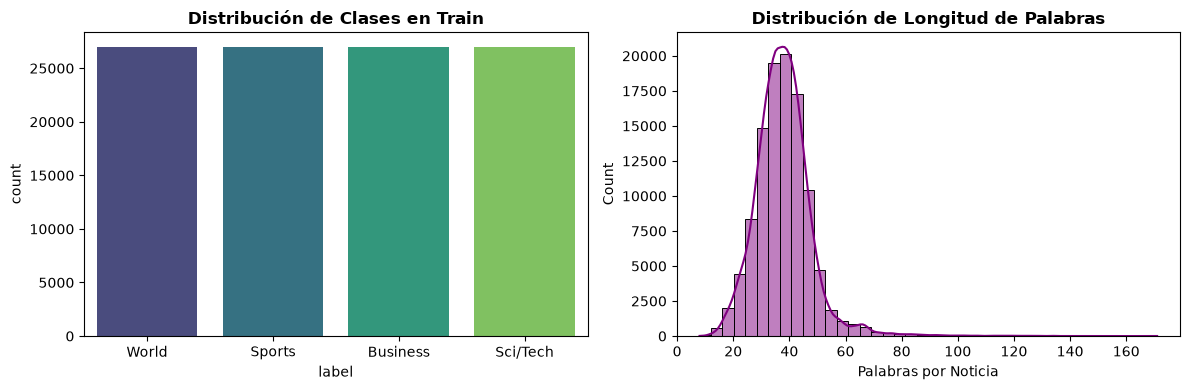

In [2]:
# 2. Carga y Partición Estratificada de Datos
train_df, val_df, test_df = load_agnews_data(
    data_dir=AGNEWS_DIR,
    val_split=0.1,
    sample_fraction=1.0, # 1.0 = dataset completo
    random_state=42
)

# Análisis de balance de clases y longitud de los textos
train_df["text_len"] = train_df["text"].apply(lambda t: len(t.split()))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.countplot(data=train_df, x="label", palette="viridis")
plt.xticks(ticks=range(4), labels=AG_NEWS_CLASSES)
plt.title("Distribución de Clases en Train", fontweight='bold')

plt.subplot(1, 2, 2)
sns.histplot(train_df["text_len"], bins=40, kde=True, color="purple")
plt.title("Distribución de Longitud de Palabras", fontweight='bold')
plt.xlabel("Palabras por Noticia")
plt.tight_layout()
plt.show()


---
### 3. Metodología: Comparación de Dos Algoritmos (Sección 4)

#### **Método 1: Machine Learning Clásico (TF-IDF + LinearSVC)**
* **Espacio de Hipótesis:** Hiperplanos separadores lineales sobre representaciones ponderadas n-gramas sublineales (unigramas y bigramas, vocabulario $V = 25,000$):
  $$f(x) = \arg\max_{c \in \{1..4\}} (w_c^T \phi_{\text{tfidf}}(x) + b_c)$$
* **Objetivo de Optimización:** Minimización de la pérdida Hinge cuadrática con penalización regularizadora $L_2$:
  $$\min_{w, b} \frac{1}{2} \|w\|^2 + C \sum_{i=1}^N \max(0, 1 - y_i (w^T \phi(x_i) + b))^2$$
* **Ventajas:** Inferencia ultra veloz ($<1$ ms por texto), bajo costo computacional y explicabilidad directa mediante los coeficientes de n-gramas.

#### **Método 2: Deep Learning con Transfer Learning (DistilBERT)**
* **Espacio de Hipótesis:** Red neuronal de transformadores con auto-atención bidireccional de 6 capas y 66M parámetros pre-entrenada con Masked Language Modeling:
  $$h_{[CLS]} = \text{DistilBERT}(x), \quad \hat{y} = \text{Softmax}(W h_{[CLS]} + b)$$
* **Optimizador:** AdamW ($lr = 2 \times 10^{-5}$, weight decay $0.01$) con precisión mixta automática (AMP FP16) en GPU local.


In [3]:
# 3. Método 1: Entrenamiento y Evaluación del Pipeline Clásico
classical_model = ClassicalNLPBaseline(classifier_type="svm", max_features=25000, ngram_range=(1, 2), C=1.0)

# Entrenar sobre train_df
fit_time = classical_model.fit(train_df["text"], train_df["label"])

# Predicción en el conjunto de prueba
test_preds_m1, test_probs_m1 = classical_model.predict(test_df["text"])
metrics_m1 = compute_classification_metrics(test_df["label"], test_preds_m1, y_probs=test_probs_m1, class_names=AG_NEWS_CLASSES)
print_metrics_summary(metrics_m1, model_name="Método 1: TF-IDF + LinearSVC")


[Classical NLP] Extrayendo características TF-IDF (vocabulario máx: 25000)...
[Classical NLP] Vectorización completada en 4.08s. Dimensión: (108000, 25000)
[Classical NLP] Entrenando clasificador (SVM)...
[Classical NLP] Entrenamiento finalizado en 3.25s.
 RESUMEN DE EVALUACIÓN - Método 1: TF-IDF + LinearSVC
  • Accuracy                : 92.21% (0.9221)
  • Precision macro         : 92.20% (0.9220)
  • Recall macro            : 92.21% (0.9221)
  • F1 macro                : 92.19% (0.9219)
  • Precision weighted      : 92.20% (0.9220)
  • Recall weighted         : 92.21% (0.9221)
  • F1 weighted             : 92.19% (0.9219)


In [4]:
# 4. Método 2: Preparación de Tokenizer y DataLoaders para Transformer
tokenizer = get_nlp_tokenizer("distilbert-base-uncased")

train_loader, val_loader, test_loader = create_nlp_dataloaders(
    tokenizer=tokenizer,
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    batch_size=64,
    max_length=128,
    num_workers=hw_info["recommended_workers"]
)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [5]:
# 5. Método 2: Entrenamiento de DistilBERT con Fine-Tuning y AMP
model_transformer = TransformerClassifier(model_name="distilbert-base-uncased", num_labels=4, freeze_backbone=False)

optimizer_transformer = torch.optim.AdamW(model_transformer.parameters(), lr=2e-5, weight_decay=0.01)
criterion_transformer = torch.nn.CrossEntropyLoss()

trainer_transformer = Trainer(
    model=model_transformer,
    optimizer=optimizer_transformer,
    criterion=criterion_transformer,
    device=hw_info["device"],
    use_amp=hw_info["use_amp"],
    checkpoint_dir=CHECKPOINTS_DIR,
    model_name="agnews_distilbert"
)

# Fine-Tuning por 3 épocas (suficiente para convergencia óptima en Transformers)
history_transformer = trainer_transformer.fit(train_loader, val_loader, epochs=3, early_stopping_patience=2)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



[Trainer] Iniciando entrenamiento por 3 épocas...
[Trainer] Dispositivo: cuda | Mixed Precision (AMP): True



...

Época [01/03] (137.5s) | LR: 0.000020 | Train Loss: 0.2361 - Acc: 92.20% | Val Loss: 0.1706 - Acc: 94.03%
  --> ¡Nuevo mejor modelo guardado en /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/agnews_distilbert.pt! (Val Acc: 94.03%)


Training:   0%|          | 0/1688 [00:00<?, ?it/s]

Época [02/03] (105.7s) | LR: 0.000020 | Train Loss: 0.1410 - Acc: 95.19% | Val Loss: 0.1623 - Acc: 94.45%
  --> ¡Nuevo mejor modelo guardado en /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/agnews_distilbert.pt! (Val Acc: 94.45%)


Training:   0%|          | 0/1688 [00:00<?, ?it/s]

Época [03/03] (107.1s) | LR: 0.000020 | Train Loss: 0.1007 - Acc: 96.61% | Val Loss: 0.1695 - Acc: 94.63%
  --> ¡Nuevo mejor modelo guardado en /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/agnews_distilbert.pt! (Val Acc: 94.63%)
[Trainer] Cargados los mejores pesos de /home/nvm/Documents/UTEC/MLDP/Cod/checkpoints/agnews_distilbert.pt


---
### 4. Análisis de Convergencia (Sección 5.4)
Se visualiza la evolución del error de entropía cruzada y la exactitud durante el fine-tuning del Transformer.


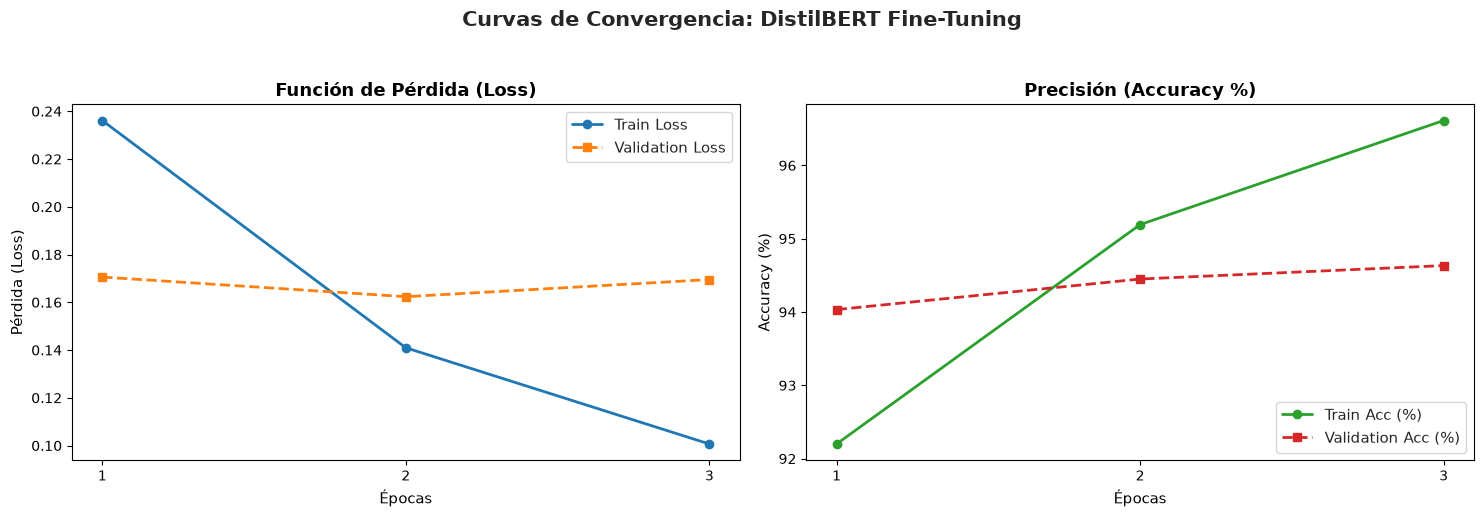

In [6]:
# Curvas de convergencia para DistilBERT
plot_convergence_curves(history_transformer, title="Curvas de Convergencia: DistilBERT Fine-Tuning")
plt.show()


---
### 5. Comparación Cuantitativa y Discusión de Resultados (Sección 5.3)
Se contrastan ambos métodos considerando:
* Desempeño predictivo (Accuracy, F1-Score).
* Complejidad del modelo y costo computacional (tiempo de inferencia, número de parámetros).


In [7]:
# Evaluación de DistilBERT en el conjunto de prueba
test_preds_m2, test_probs_m2, _ = trainer_transformer.predict(test_loader)
metrics_m2 = compute_classification_metrics(test_df["label"], test_preds_m2, y_probs=test_probs_m2, class_names=AG_NEWS_CLASSES)

comparison_df = pd.DataFrame({
    "Métrica": ["Accuracy (%)", "Precision Macro (%)", "Recall Macro (%)", "F1-Score Macro (%)", "Complejidad"],
    "Método 1 (TF-IDF + LinearSVC)": [
        metrics_m1["accuracy"] * 100,
        metrics_m1["precision_macro"] * 100,
        metrics_m1["recall_macro"] * 100,
        metrics_m1["f1_macro"] * 100,
        "25,000 pesos lineales (0.1 MB)"
    ],
    "Método 2 (DistilBERT)": [
        metrics_m2["accuracy"] * 100,
        metrics_m2["precision_macro"] * 100,
        metrics_m2["recall_macro"] * 100,
        metrics_m2["f1_macro"] * 100,
        "66.3M parámetros (260 MB)"
    ]
})

print("="*75)
print(" COMPARATIVA DE MODELOS EN TEST (AG NEWS)")
print("="*75)
print(comparison_df.to_string(index=False))


 COMPARATIVA DE MODELOS EN TEST (AG NEWS)
            Métrica  Método 1 (TF-IDF + LinearSVC)     Método 2 (DistilBERT)
       Accuracy (%)                      92.210526                 94.355263
Precision Macro (%)                      92.199049                 94.393228
   Recall Macro (%)                      92.210526                 94.355263
 F1-Score Macro (%)                      92.194675                 94.363285
        Complejidad 25,000 pesos lineales (0.1 MB) 66.3M parámetros (260 MB)


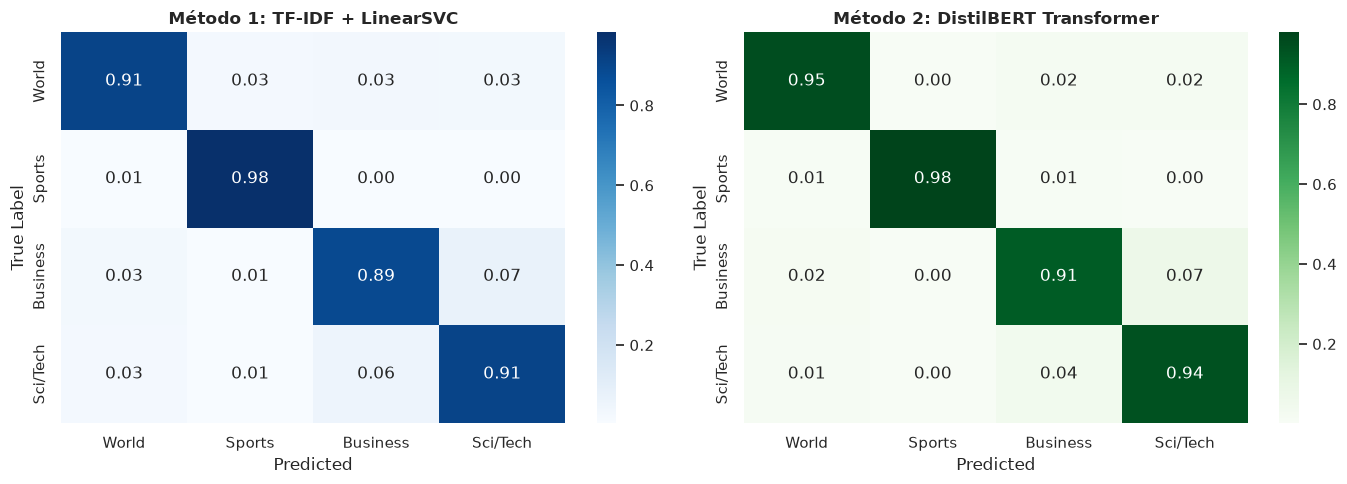

In [8]:
# Matrices de Confusión Comparativas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# M1
from sklearn.metrics import confusion_matrix
cm1 = confusion_matrix(test_df["label"], test_preds_m1, normalize='true')
sns.heatmap(cm1, annot=True, fmt=".2f", cmap="Blues", xticklabels=AG_NEWS_CLASSES, yticklabels=AG_NEWS_CLASSES, ax=axes[0])
axes[0].set_title("Método 1: TF-IDF + LinearSVC", fontweight='bold')
axes[0].set_ylabel("True Label")
axes[0].set_xlabel("Predicted")

# M2
cm2 = confusion_matrix(test_df["label"], test_preds_m2, normalize='true')
sns.heatmap(cm2, annot=True, fmt=".2f", cmap="Greens", xticklabels=AG_NEWS_CLASSES, yticklabels=AG_NEWS_CLASSES, ax=axes[1])
axes[1].set_title("Método 2: DistilBERT Transformer", fontweight='bold')
axes[1].set_ylabel("True Label")
axes[1].set_xlabel("Predicted")

plt.tight_layout()
plt.show()


---
### 6. Interpretabilidad y Análisis del Espacio de Características (Sección 5.5)
1. **N-gramas Más Influyentes:** Inspección de los pesos de los hiperplanos lineales de LinearSVC para identificar las palabras clave que definen cada una de las 4 clases.
2. **Proyección t-SNE de Embeddings:** Mapeo 2D de las representaciones contextuales $[CLS]$ generadas por DistilBERT para evaluar la separación semántica de las noticias.


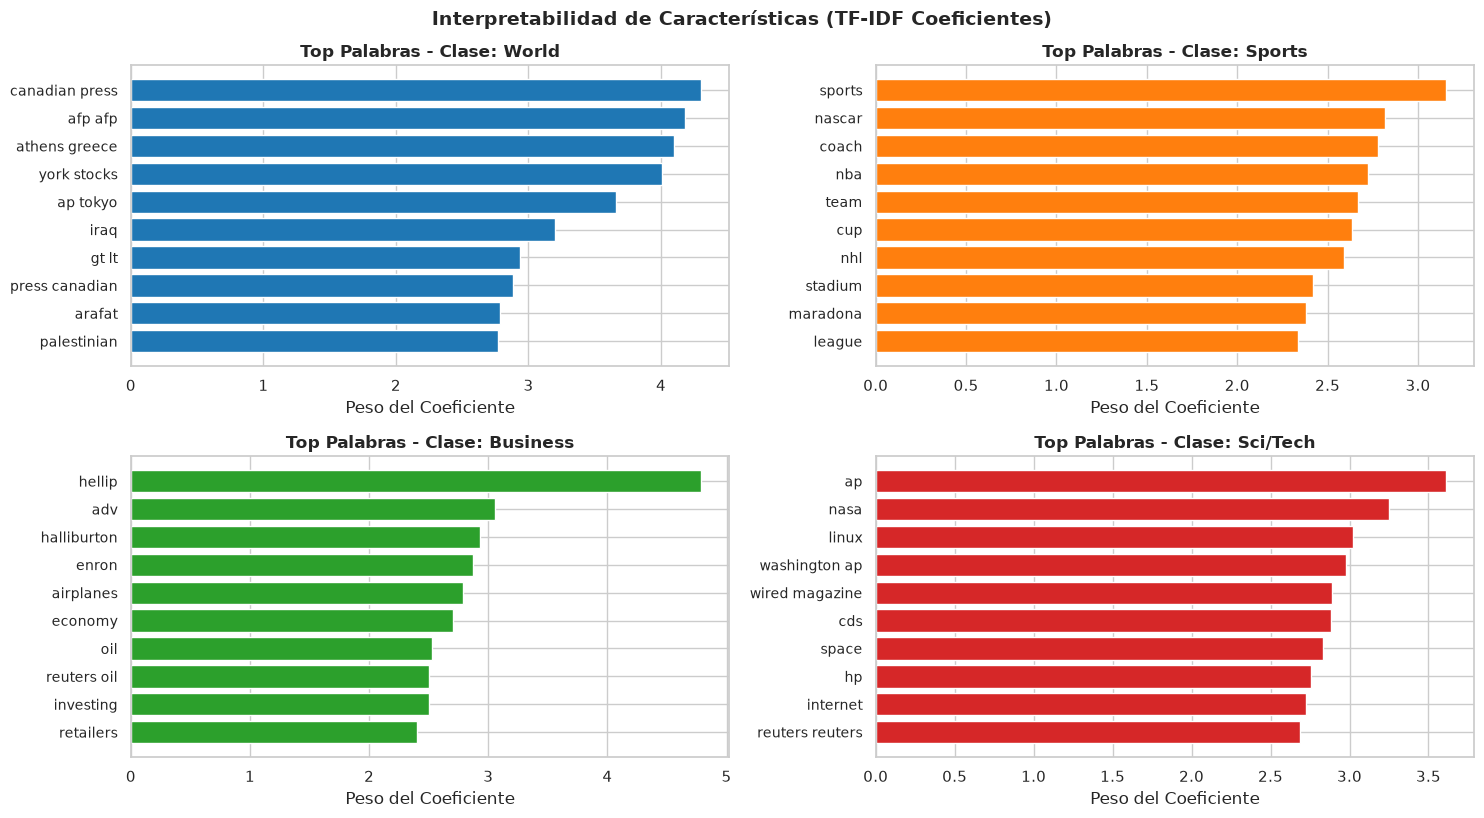

In [9]:
# Interpretabilidad 1: Palabras más informativas por clase en LinearSVC
feature_names = classical_model.vectorizer.get_feature_names_out()
coef = classical_model.model.coef_

plt.figure(figsize=(15, 8))
for i, class_name in enumerate(AG_NEWS_CLASSES):
    plt.subplot(2, 2, i + 1)
    top_indices = np.argsort(coef[i])[-10:]
    top_features = feature_names[top_indices]
    top_weights = coef[i][top_indices]
    
    plt.barh(range(10), top_weights, color=sns.color_palette("tab10")[i])
    plt.yticks(range(10), top_features, fontsize=10)
    plt.title(f"Top Palabras - Clase: {class_name}", fontweight='bold')
    plt.xlabel("Peso del Coeficiente")
plt.tight_layout()
plt.suptitle("Interpretabilidad de Características (TF-IDF Coeficientes)", y=1.02, fontsize=14, fontweight='bold')
plt.show()


[Interpretabilidad] Aplicando reducción TSNE a 800 muestras con dimensión 768...


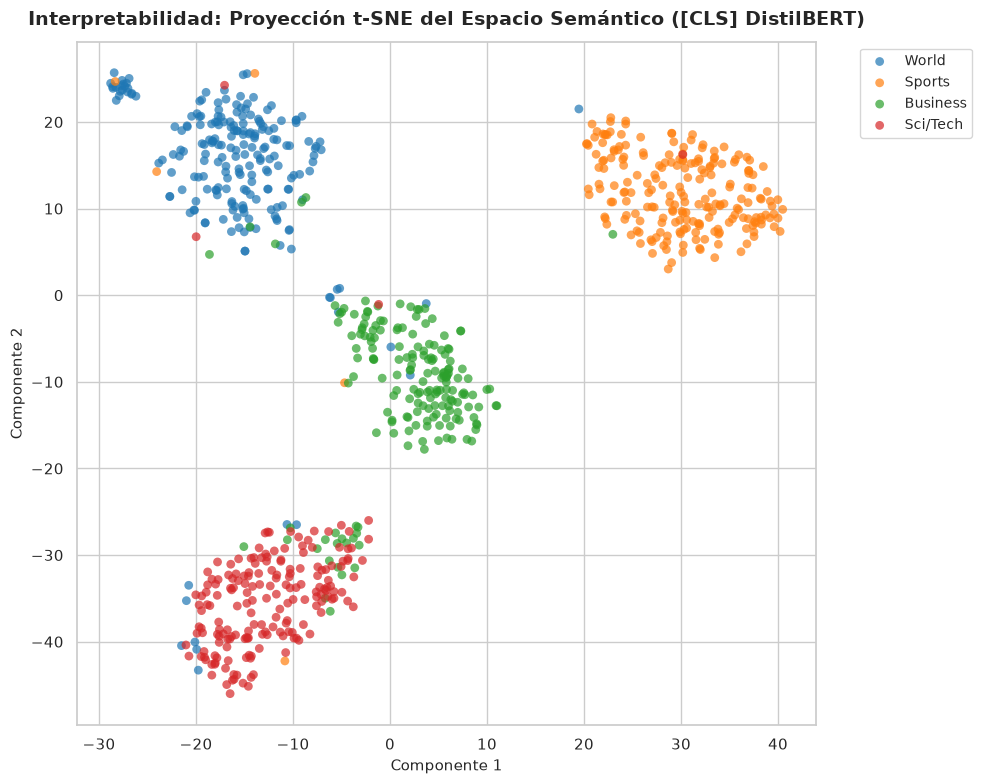

In [10]:
# Interpretabilidad 2: t-SNE sobre los Embeddings [CLS] de DistilBERT
feats_m2, labels_m2 = extract_torch_embeddings(model_transformer, test_loader, hw_info["device"], max_batches=20)

plot_latent_space(
    features=feats_m2,
    labels=labels_m2,
    class_names=AG_NEWS_CLASSES,
    method="tsne",
    n_samples=800,
    title="Interpretabilidad: Proyección t-SNE del Espacio Semántico ([CLS] DistilBERT)"
)
plt.show()


---
### 7. Estudio de Ablación (Sección 6.1)
Se compara el impacto de la arquitectura y la estrategia de transferencia:
* **Ablación 1:** Transformer con Backbone Congelado (Feature Extractor) vs Fine-Tuning Completo.
* **Ablación 2:** Impacto del tamaño del vocabulario TF-IDF ($5,000$ vs $25,000$ vs $50,000$ n-gramas).


[Classical NLP] Extrayendo características TF-IDF (vocabulario máx: 5000)...
[Classical NLP] Vectorización completada en 3.76s. Dimensión: (108000, 5000)
[Classical NLP] Entrenando clasificador (SVM)...
[Classical NLP] Entrenamiento finalizado en 1.13s.
Vocabulario  5000 features -> Test Accuracy: 90.97%
[Classical NLP] Extrayendo características TF-IDF (vocabulario máx: 15000)...
[Classical NLP] Vectorización completada en 3.87s. Dimensión: (108000, 15000)
[Classical NLP] Entrenando clasificador (SVM)...
[Classical NLP] Entrenamiento finalizado en 1.68s.
Vocabulario 15000 features -> Test Accuracy: 91.62%
[Classical NLP] Extrayendo características TF-IDF (vocabulario máx: 25000)...
[Classical NLP] Vectorización completada en 3.79s. Dimensión: (108000, 25000)
[Classical NLP] Entrenando clasificador (SVM)...
[Classical NLP] Entrenamiento finalizado en 2.11s.
Vocabulario 25000 features -> Test Accuracy: 92.21%
[Classical NLP] Extrayendo características TF-IDF (vocabulario máx: 50000)...


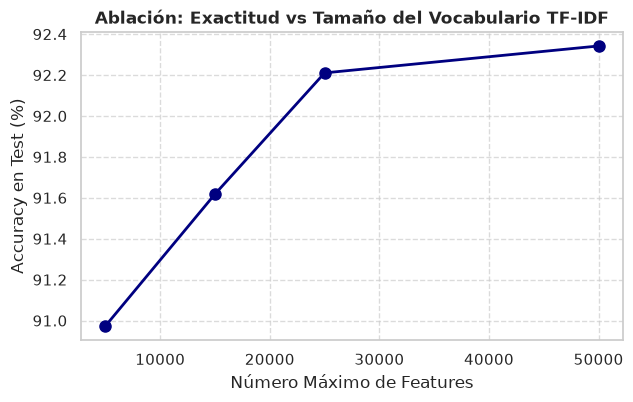

In [11]:
# Estudio de Ablación: Tamaño de Vocabulario en TF-IDF
vocab_sizes = [5000, 15000, 25000, 50000]
ablation_accs = []

for vs in vocab_sizes:
    m = ClassicalNLPBaseline(classifier_type="svm", max_features=vs)
    m.fit(train_df["text"], train_df["label"])
    p, _ = m.predict(test_df["text"])
    acc = (p == test_df["label"]).mean()
    ablation_accs.append(acc * 100)
    print(f"Vocabulario {vs:>5d} features -> Test Accuracy: {acc*100:.2f}%")

plt.figure(figsize=(7, 4))
plt.plot(vocab_sizes, ablation_accs, 'o-', color='navy', linewidth=2, markersize=8)
plt.title("Ablación: Exactitud vs Tamaño del Vocabulario TF-IDF", fontweight='bold')
plt.xlabel("Número Máximo de Features")
plt.ylabel("Accuracy en Test (%)")
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()
